In [1]:
from shapely.geometry import Polygon, Point
import shapely
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.spatial import Voronoi, voronoi_plot_2d
from scipy.spatial import Voronoi, voronoi_plot_2d

from artistic_pattern_gen import generate_points, points_on_polygon_boundary, cell_polygons, compare_points, goal_generation, create_rectangle, create_circle, create_triangle

/home/mariia/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# Create a circle
circle_center = (-1.5, -1.5)
circle_radius = 1.5
circle_polygon = create_circle(circle_center, circle_radius)

# Create a triangle
triangle_vertices = [(1.5, -2.5), (4.5, -2.5), (3, 1)]
triangle_polygon = create_triangle(triangle_vertices)

# Create a rectangle
rectangle_lower_left = (-1.5, 1.5)
rectangle_upper_right = (1.5, 4.5)
rectangle_polygon = create_rectangle(rectangle_lower_left, rectangle_upper_right)


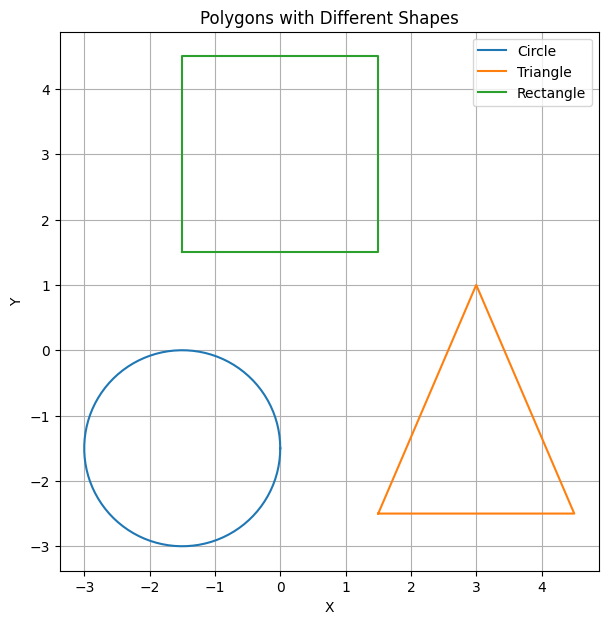

In [3]:
# Plot polygons
plt.figure(figsize=(7,7))
plt.plot(*circle_polygon.exterior.xy, label='Circle')
plt.plot(*triangle_polygon.exterior.xy, label='Triangle')
plt.plot(*rectangle_polygon.exterior.xy, label='Rectangle')
plt.gca().set_aspect('equal', adjustable='box')
plt.legend()
plt.title('Polygons with Different Shapes')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True)
plt.show()


## Base voronoi partition

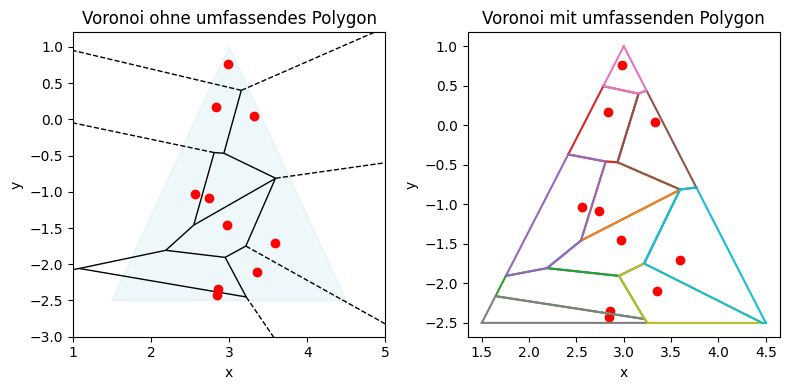

In [39]:
polygon = triangle_polygon
points = generate_points(10, polygon)
points = np.array([[point.x, point.y] for point in points])

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(8,4))

# voronoi without containing polygon
vor = Voronoi(points)
voronoi_plot_2d(vor, ax=ax1, show_points=False, show_vertices=False)
ax1.plot(points[:,0], points[:,1], 'ro')  # Plot the points
x, y = polygon.exterior.xy
ax1.fill(x,y, color="lightblue", alpha=0.2)

# voronoi with containing polygon
voronoi_polygons = cell_polygons(points, polygon)
for point in points:
    ax2.scatter(point[0], point[1], color='red')

for cell in voronoi_polygons:
    ax2.plot(*cell.exterior.xy)

ax1.set_xlim([1,5])
ax1.set_ylim([-3, 1.2])

ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title("Voronoi ohne umfassendes Polygon")

ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_title("Voronoi mit umfassenden Polygon")


plt.tight_layout()
plt.savefig("plots/voronoi.png")
plt.show()

## Buffer voronoi

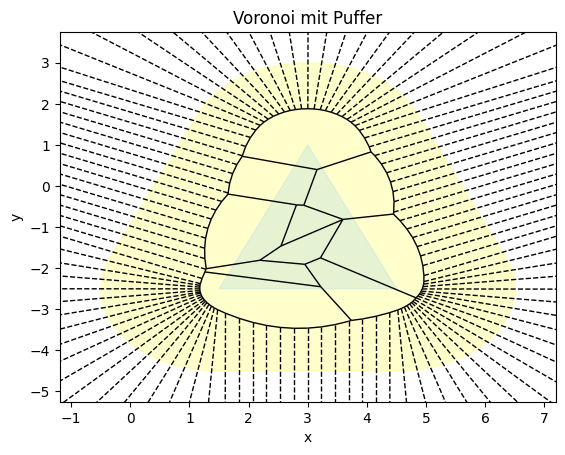

In [55]:
buffer = polygon.buffer(2)
buffer_points = points_on_polygon_boundary(buffer, 100)
all_points = np.vstack((buffer_points, points))
vor = Voronoi(all_points)

fig, ax = plt.subplots()
ax.fill(*buffer.exterior.xy, color='yellow', alpha=0.2)
ax.fill(*polygon.exterior.xy, color='lightblue', alpha=0.3)
voronoi_plot_2d(vor, ax=ax, show_points=False, show_vertices=False)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title("Voronoi mit Puffer")

plt.savefig("plots/voronoi_buffer.png")

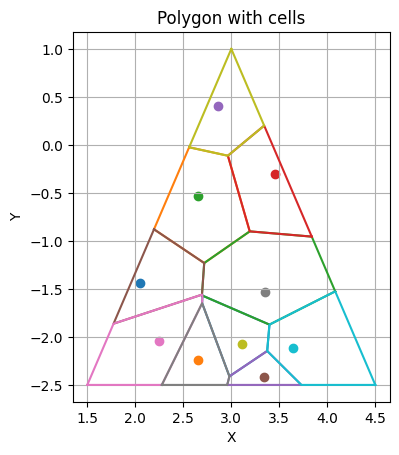

In [13]:
plt.figure()
#plt.plot(*polygon.exterior.xy)

for point in points:
    plt.scatter(point[0], point[1])

for cell in voronoi_polygons:
    plt.plot(*cell.exterior.xy)

plt.gca().set_aspect('equal', adjustable='box')
plt.title('Polygon with cells')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True)
plt.show()

In [12]:
# generate random points in polygon
points = generate_points(10, triangle_polygon)
points = np.array([[point.x, point.y] for point in points])
voronoi_polygons = cell_polygons(points, triangle_polygon)

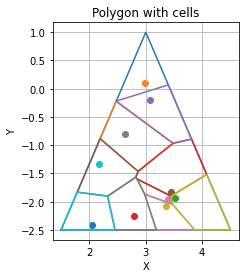

In [14]:
plt.figure()
plt.plot(*triangle_polygon.exterior.xy)

for point in points:
    plt.scatter(point[0], point[1])

for cell in voronoi_polygons:
    plt.plot(*cell.exterior.xy)

plt.gca().set_aspect('equal', adjustable='box')
plt.title('Polygon with cells')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True)
plt.show()

Iteration:  False


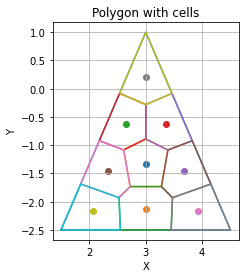

In [18]:
polygon = triangle_polygon
goal_positions = goal_generation(polygon, 10)
voronoi_polygons = cell_polygons(goal_positions, polygon)

plt.figure()
plt.plot(*polygon.exterior.xy)

for point in goal_positions:
    plt.scatter(point[0], point[1])

for cell in voronoi_polygons:
    plt.plot(*cell.exterior.xy)

plt.gca().set_aspect('equal', adjustable='box')
plt.title('Polygon with cells')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True)
plt.show()